# 04 — Evaluation: RF vs SVM vs DT on the five study metrics
**MSc AI dissertation · Ghanem Almarar · Phase 4**

Implementation: [`src/evaluation.py`](../src/evaluation.py). This notebook re-runs it and walks through the
outputs that go into Chapter 4 (Results) and Chapter 5 (Discussion). Interpretation notes: `docs/results_notes.md`.

**Metric definitions used throughout**
* accuracy; precision / recall / F1 — *weighted* average across the 5 classes (as stated in the proposal);
* **FPR (Normal)** = truly-Normal records predicted as *any* attack ÷ all truly-Normal records — "normal traffic
  falsely flagged as malicious": the alert-fatigue metric;
* macro-F1 is reported as an extra because the weighted average hides the tiny R2L/U2R classes.

**Two test sets, on purpose (decision D2):** the 20 % holdout of KDDTrain+ (same distribution as training) and
the official KDDTest+ (17 attack types never seen in training). Reporting both is what separates this study from
most of the literature.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import evaluation as ev
perf = ev.run()        # regenerates every table and figure (fast: predictions are pre-computed)

        model                 test_set  accuracy  precision_weighted  recall_weighted  f1_weighted  fpr_normal  f1_macro  fit_seconds  predict_holdout_seconds  predict_official_seconds
Random Forest 20 % holdout (KDDTrain+)    0.9926              0.9926           0.9926       0.9926      0.0073    0.9520        2.249                    0.039                     0.039
Random Forest      KDDTest+ (official)    0.7203              0.7819           0.7203       0.6845      0.0711    0.5039        2.249                    0.039                     0.039
    SVM (RBF) 20 % holdout (KDDTrain+)    0.9463              0.9605           0.9463       0.9507      0.0836    0.7055      111.991                   40.627                    36.442
    SVM (RBF)      KDDTest+ (official)    0.7155              0.7292           0.7155       0.6979      0.0901    0.5424      111.991                   40.627                    36.442
Decision Tree 20 % holdout (KDDTrain+)    0.9910              0.9910       

## Master comparison table (Ch4)

In [2]:
cols = ["model","test_set","accuracy","precision_weighted","recall_weighted","f1_weighted","fpr_normal","f1_macro"]
perf[cols].round(4)

,model,test_set,accuracy,precision_weighted,recall_weighted,f1_weighted,fpr_normal,f1_macro
0,Random Forest,20 % holdout (KDDTrain+),0.9926,0.9926,0.9926,0.9926,0.0073,0.9520
1,Random Forest,KDDTest+ (official),0.7203,0.7819,0.7203,0.6845,0.0711,0.5039
2,SVM (RBF),20 % holdout (KDDTrain+),0.9463,0.9605,0.9463,0.9507,0.0836,0.7055
3,SVM (RBF),KDDTest+ (official),0.7155,0.7292,0.7155,0.6979,0.0901,0.5424
4,Decision Tree,20 % holdout (KDDTrain+),0.9910,0.9910,0.9910,0.9910,0.0095,0.9421
5,Decision Tree,KDDTest+ (official),0.7123,0.7657,0.7123,0.6782,0.0738,0.5152


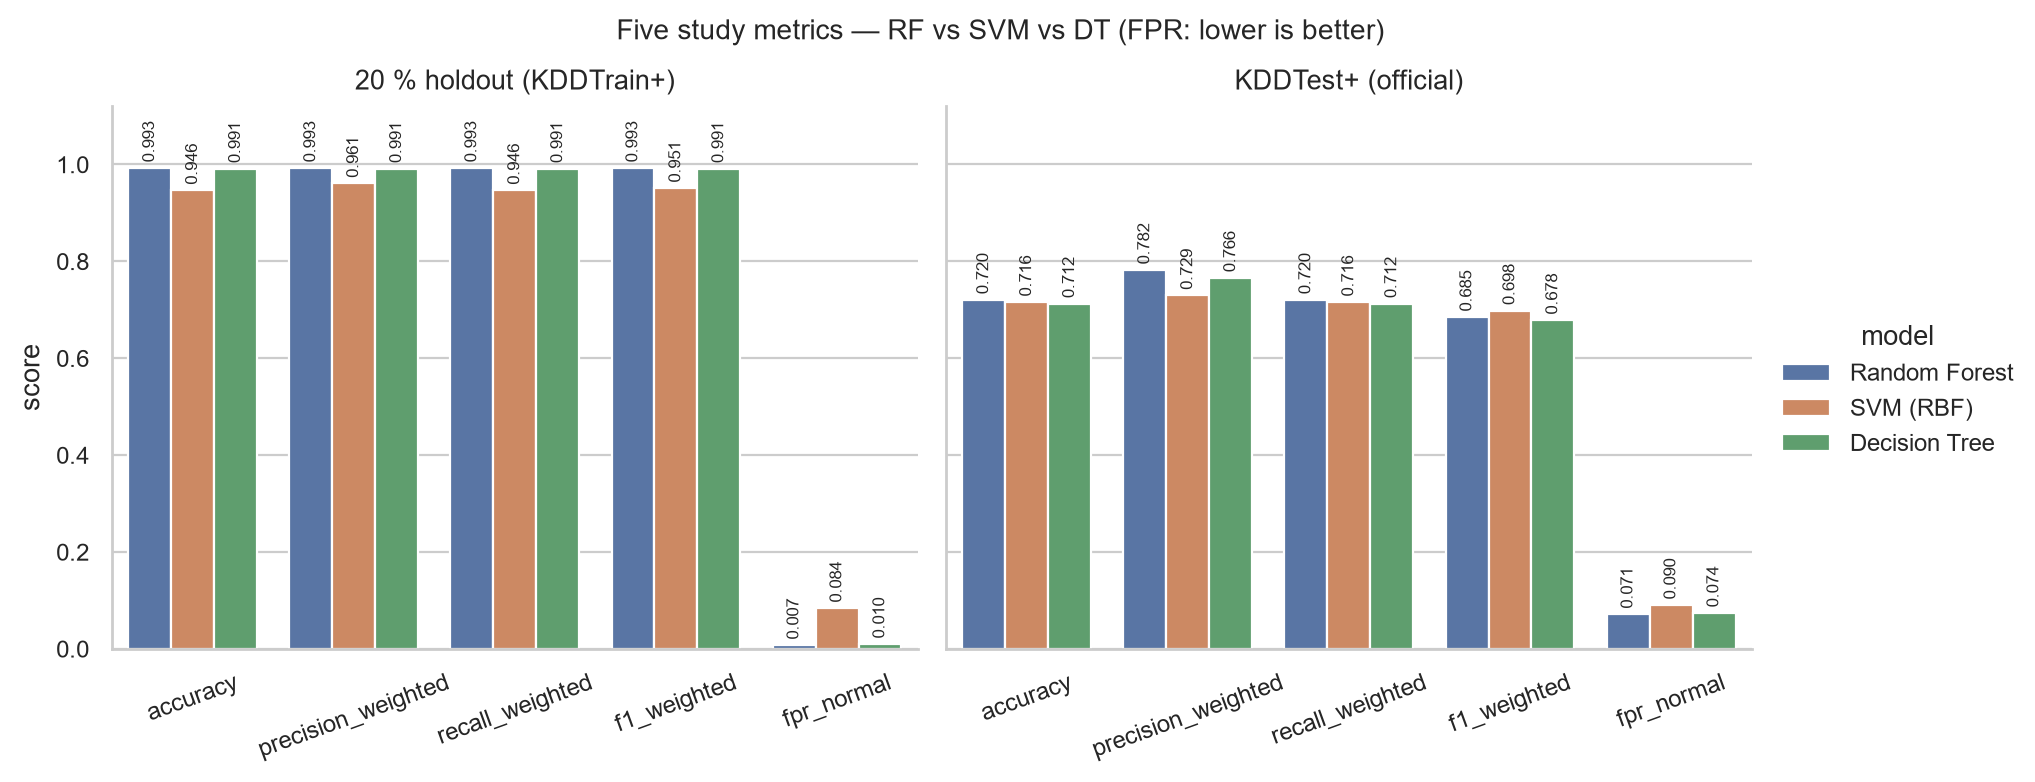

In [3]:
display(Image(str(ROOT/"results/figures/fig_metric_comparison.png"), width=950))

**Reading it.** On the in-distribution holdout Random Forest leads on every metric and has the lowest FPR (0.7 %);
Decision Tree is within 0.2 pp; SVM trails by ~4 pp and has a 10× higher FPR. On KDDTest+ all three fall to
≈ 72 % accuracy — the gap between the two panels is the dataset's distribution shift, not an algorithm effect.

## Cross-validation stability (Ch4)

In [4]:
pd.read_csv(ROOT/"results/tables/cv_results_summary.csv", index_col=0)[
    ["test_accuracy_mean","test_accuracy_std","test_f1_weighted_mean","test_f1_weighted_std"]]

,test_accuracy_mean,test_accuracy_std,test_f1_weighted_mean,test_f1_weighted_std
model,,,,
decision_tree,0.9955,0.0005,0.9955,0.0005
random_forest,0.9970,0.0003,0.9970,0.0003
svm_rbf,0.9556,0.0013,0.9555,0.0013


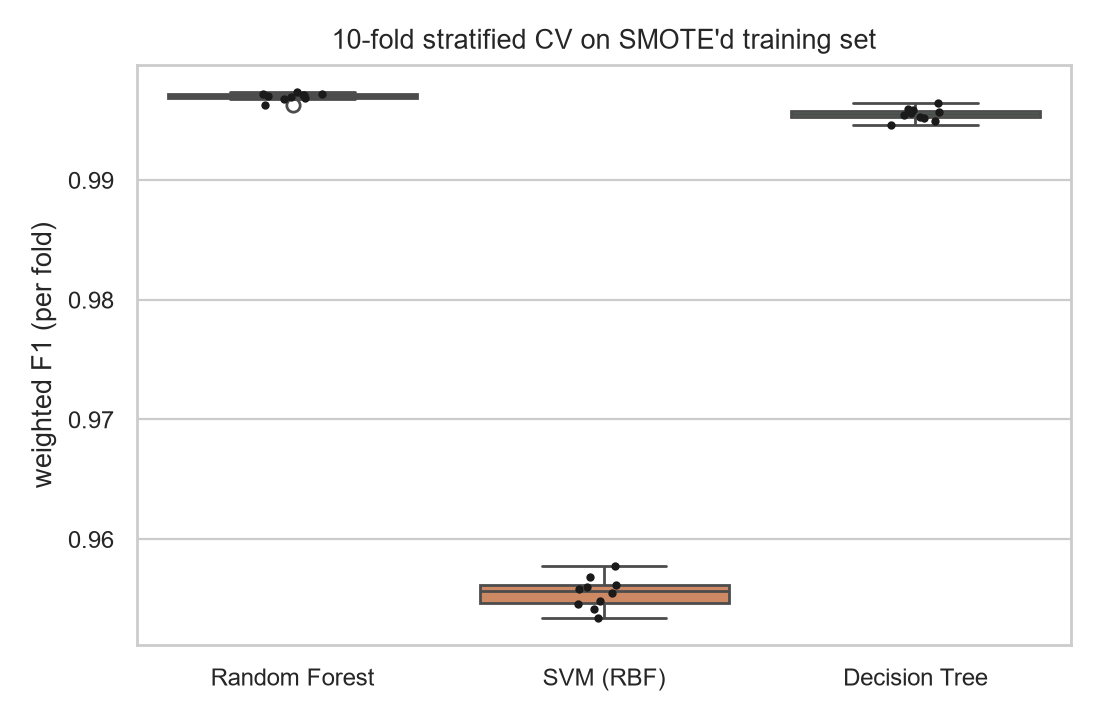

In [5]:
display(Image(str(ROOT/"results/figures/fig_cv_f1_boxplot.png"), width=520))

## Where the models fail — per-class recall (RQ3 + fairness)

In [6]:
pc = pd.read_csv(ROOT/"results/tables/per_class_metrics.csv")
pc.pivot_table(index=["test_set","class"], columns="model", values="recall").round(3)

model                            Decision Tree  Random Forest  SVM (RBF)
test_set                 class                                          
20 % holdout (KDDTrain+) DoS             0.997          0.996      0.981
                         Normal          0.990          0.993      0.916
                         Probe           0.978          0.983      0.982
                         R2L             0.925          0.930      0.930
                         U2R             0.700          0.800      0.900
KDDTest+ (official)      DoS             0.734          0.750      0.702
                         Normal          0.926          0.929      0.910
                         Probe           0.544          0.575      0.587
                         R2L             0.092          0.077      0.214
                         U2R             0.134          0.075      0.358

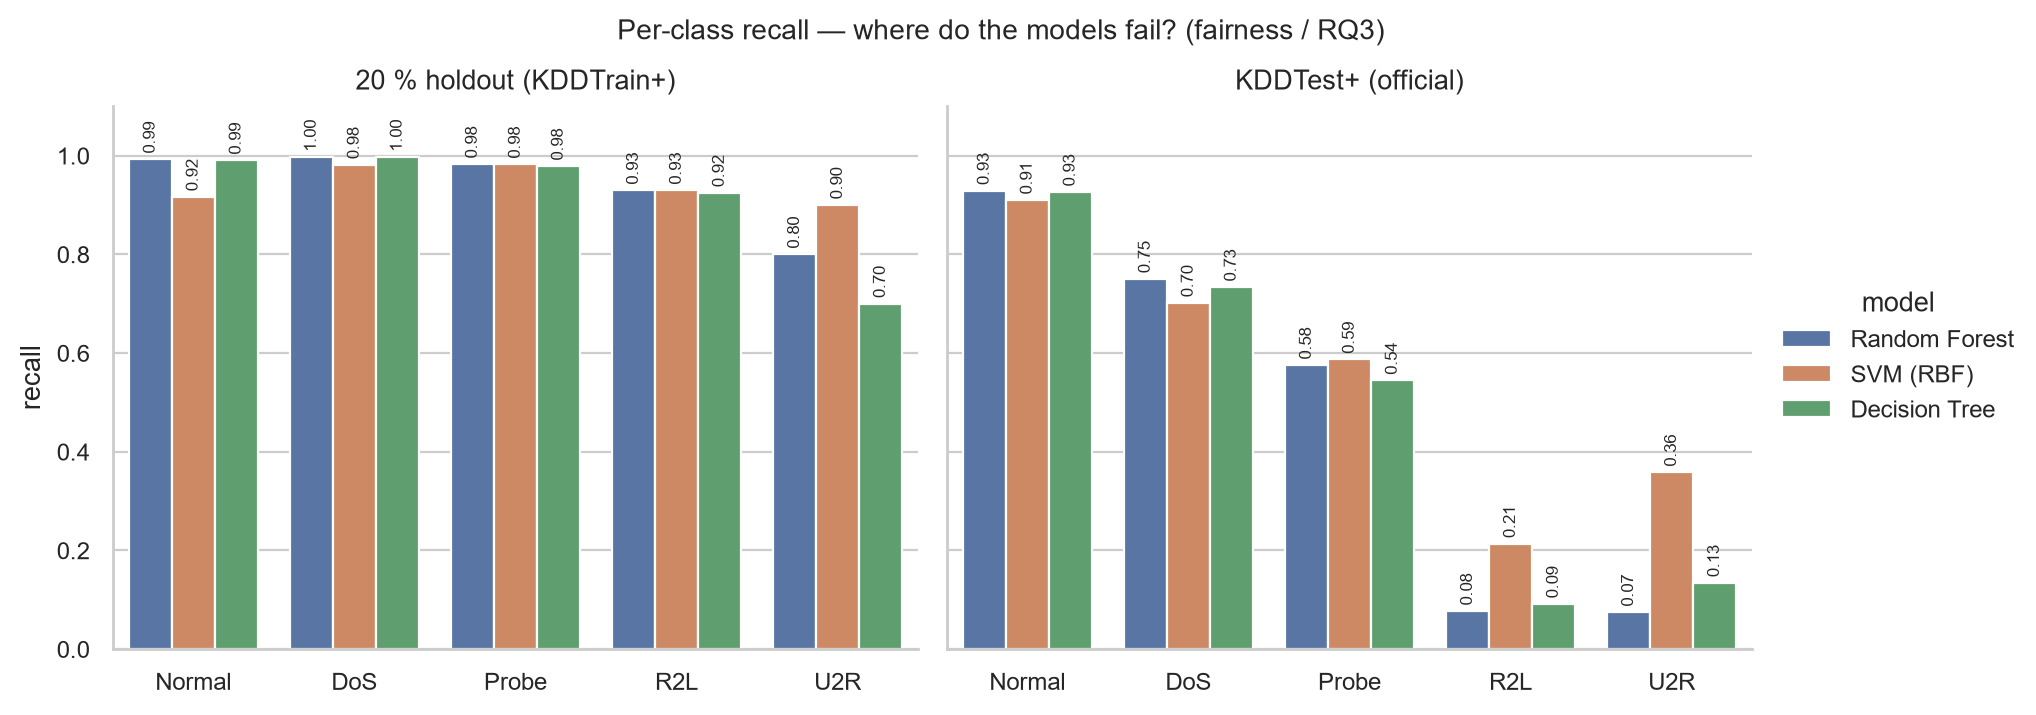

In [7]:
display(Image(str(ROOT/"results/figures/fig_per_class_recall.png"), width=950))

R2L and U2R recall collapses on KDDTest+ (RF 0.08 / 0.07). SMOTE balanced the *training* classes but cannot
invent attack signatures that were never in KDDTrain+. SVM's smoother decision boundary recovers noticeably more
of them (0.21 / 0.36) — at the price of FPR and speed.

## Confusion matrices

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, m in enumerate(["random_forest","svm_rbf","decision_tree"]):
    for i, s in enumerate(["holdout","official"]):
        axes[i, j].imshow(plt.imread(ROOT/f"results/figures/cm_{m}_{s}.png")); axes[i, j].axis("off")
plt.tight_layout(); plt.show()

C:\Users\PC\AppData\Local\Temp\ipykernel_34124\226599252.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## Computational cost (RQ2)

In [9]:
pd.read_csv(ROOT/"results/tables/timing.csv")

,model,fit_seconds,predict_holdout_seconds,predict_official_seconds,n_train,n_holdout,n_official,predict_holdout_us_per_row
0,random_forest,2.249,0.039,0.039,269370,25195,22544,1.54
1,svm_rbf,111.991,40.627,36.442,269370,25195,22544,1612.49
2,decision_tree,0.864,0.002,0.001,269370,25195,22544,0.08


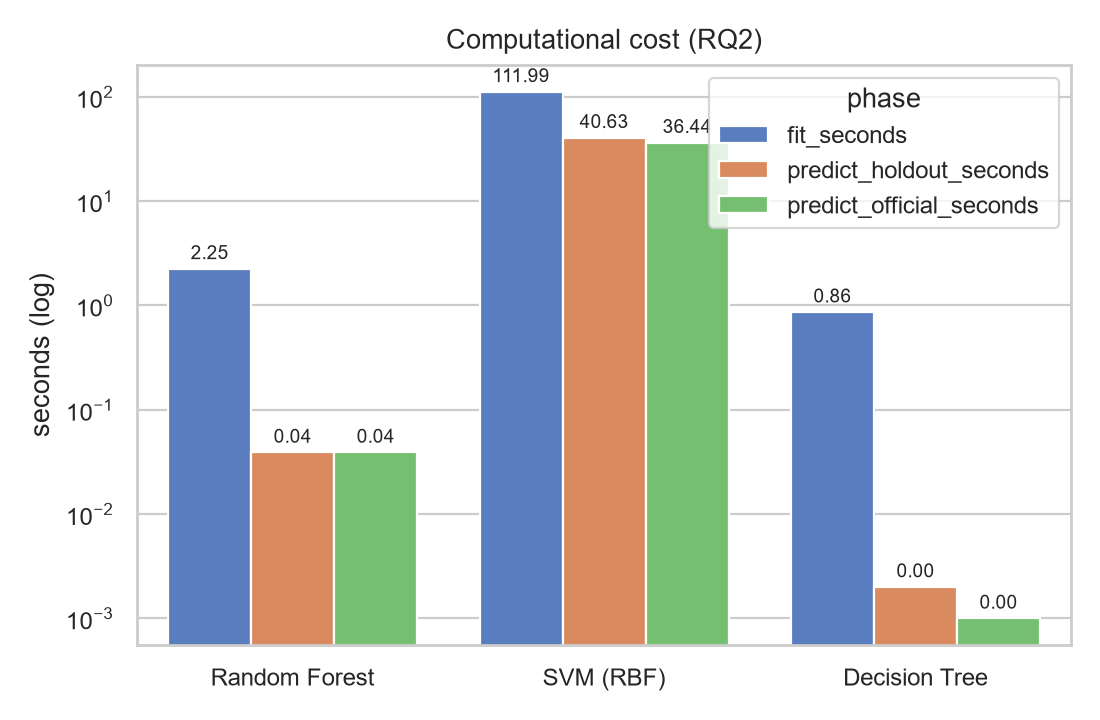

In [10]:
display(Image(str(ROOT/"results/figures/fig_timing.png"), width=520))

SVM costs ~50× RF to fit and ~1,000× RF to predict (≈ 1.6 ms per flow) — a real constraint for an IDS that must
score traffic continuously. Decision Tree is cheapest; Random Forest is the best FPR/cost trade-off.

## Carry into the dissertation
* **Ch4:** master table, CV table, per-class table, Figures: metric comparison, CV box-plot, per-class recall,
  confusion matrices (holdout + KDDTest+), timing.
* **Ch5:** RQ1 — RF best in-distribution, near-tie out-of-distribution; RQ2 — RF lowest FPR, DT fastest, SVM
  slow + high FPR; RQ3 — distribution shift dominates, minority classes collapse, SVM generalises slightly better.